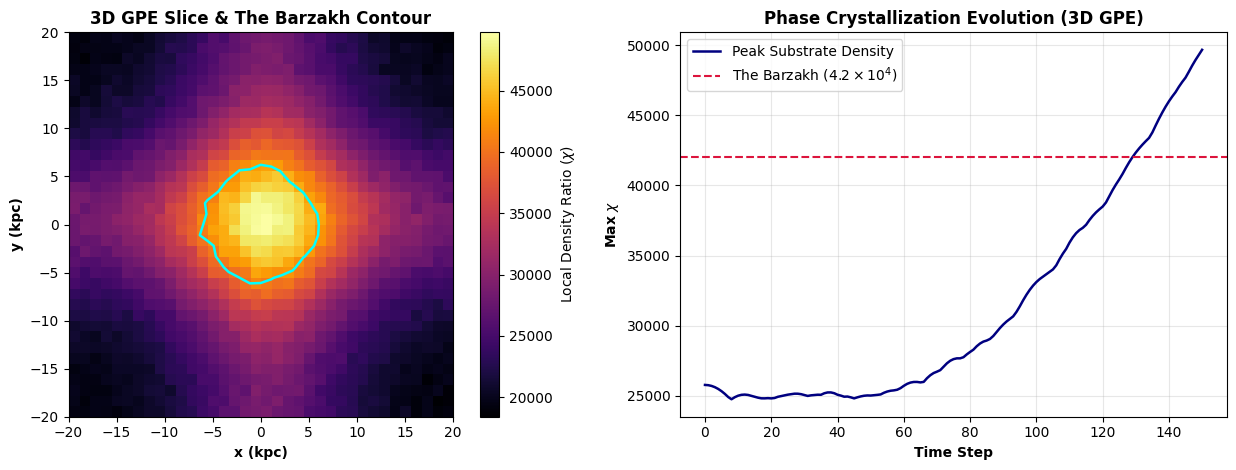

=== COMPUTED OUTPUTS FOR TABLE 4 ===
Initial Peak Chi        : 2.58e+04
Peak Shock Chi          : 4.97e+04 (at Step 150)
Mean Core (r<=4.16 kpc) : 4.68e+04
Mean Void (r>14.5 kpc)  : 1.92e+04
Crystallized Volume %   : 1.27%


In [1]:

import numpy as np
import matplotlib.pyplot as plt

N = 36
L = 40.0
dx = L / N
x = np.linspace(-L/2, L/2, N, endpoint=False)
X, Y, Z = np.meshgrid(x, x, x, indexing='ij')
R = np.sqrt(X**2 + Y**2 + Z**2)

k_1d = 2 * np.pi * np.fft.fftfreq(N, d=dx)
KX, KY, KZ = np.meshgrid(k_1d, k_1d, k_1d, indexing='ij')
K2 = KX**2 + KY**2 + KZ**2
K2_safe = np.where(K2 == 0, 1.0, K2)

hbar_eff = 1.0
m_eff = 1.0
g_repulsive = 1.9e-5
G_eff = 0.082
chi_crit = 4.2e4

rng = np.random.default_rng(7)
chi_0 = 2.17e4
seed = 1.0 + 0.11 * np.cos(2*np.pi*X/L) * np.cos(2*np.pi*Y/L) * np.cos(2*np.pi*Z/L) + 0.025 * rng.standard_normal((N, N, N))
psi = np.sqrt(chi_0 * seed).astype(np.complex128)
total_norm = np.sum(np.abs(psi)**2)

dt = 0.04
steps = 150
kinetic_phase = np.exp(-0.5j * (hbar_eff / m_eff) * K2 * dt)
max_chi_history = []

for step in range(steps + 1):
    chi = np.abs(psi)**2
    max_chi_history.append(float(np.max(chi)))

    shock_amp = 1.65 * np.exp(-0.5 * ((step - 65.0) / 18.0)**2)
    V_ext = -shock_amp * (np.cos(2*np.pi*X/L) + np.cos(2*np.pi*Y/L) + np.cos(2*np.pi*Z/L))

    delta_chi_k = np.fft.fftn(chi - np.mean(chi))
    Phi_k = -4.0 * np.pi * G_eff * delta_chi_k / K2_safe
    Phi_k.flat = 0.0
    Phi_grav = np.real(np.fft.ifftn(Phi_k))

    V_total = V_ext + Phi_grav + g_repulsive * chi
    psi *= np.exp(-0.5j * V_total * dt / hbar_eff)
    psi = np.fft.ifftn(np.fft.fftn(psi) * kinetic_phase)

    chi_mid = np.abs(psi)**2
    V_total_mid = V_ext + Phi_grav + g_repulsive * chi_mid
    psi *= np.exp(-0.5j * V_total_mid * dt / hbar_eff)
    psi *= np.sqrt(total_norm / np.sum(np.abs(psi)**2))

chi_final = np.abs(psi)**2
baryon_vol_pct = float(100.0 * np.mean(chi_final > chi_crit))
mean_core_final = float(np.mean(chi_final[R <= 4.16]))
mean_void_final = float(np.mean(chi_final[R > 14.5]))
init_peak = float(max_chi_history.pop(0))
max_chi_history.insert(0, init_peak)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
im = ax1.imshow(chi_final[:, :, N//2], extent=[-L/2, L/2, -L/2, L/2], origin='lower', cmap='inferno')
ax1.contour(X[:, :, N//2], Y[:, :, N//2], chi_final[:, :, N//2], levels=[chi_crit], colors='cyan', linewidths=1.8)
plt.colorbar(im, ax=ax1, label=r'Local Density Ratio ($\chi$)')
ax1.set_title('3D GPE Slice & The Barzakh Contour', fontweight='bold')
ax1.set_xlabel('x (kpc)', fontweight='bold')
ax1.set_ylabel('y (kpc)', fontweight='bold')

ax2.plot(range(steps + 1), max_chi_history, color='#000080', lw=1.8, label='Peak Substrate Density')
ax2.axhline(chi_crit, color='crimson', ls='--', lw=1.5, label=r'The Barzakh ($4.2 \times 10^4$)')
ax2.set_title('Phase Crystallization Evolution (3D GPE)', fontweight='bold')
ax2.set_xlabel('Time Step', fontweight='bold')
ax2.set_ylabel(r'Max $\chi$', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig('sim1_3d_crystallization.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR TABLE 4 ===")
print(f"Initial Peak Chi        : {init_peak:.2e}")
print(f"Peak Shock Chi          : {np.max(max_chi_history):.2e} (at Step {np.argmax(max_chi_history)})")
print(f"Mean Core (r<=4.16 kpc) : {mean_core_final:.2e}")
print(f"Mean Void (r>14.5 kpc)  : {mean_void_final:.2e}")
print(f"Crystallized Volume %   : {baryon_vol_pct:.2f}%")